In [1]:
!pip install mysql-connector-python pandas


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [24]:
import pandas as pd
import mysql.connector

# 1. Configuration de la connexion
db_config = {
    'host': 'localhost',
    'user': 'root', 
    'password': 'Password21',
    'database': 'classicmodels'
}

# 2. Connexion à la base
try:
    conn = mysql.connector.connect(**db_config)
    print("✅ Connexion réussie à MySQL !")
    
    # 3. Petit test pour voir si on récupère des données
    df_test = pd.read_sql("SELECT customerName, city, country FROM customers LIMIT 5", conn)
    display(df_test)
    
except Exception as e:
    print(f"❌ Erreur de connexion : {e}")

✅ Connexion réussie à MySQL !


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/732113366.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql("SELECT customerName, city, country FROM customers LIMIT 5", conn)


,customerName,city,country
0,Atelier graphique,Nantes,France
1,Signal Gift Stores,Las Vegas,USA
2,"Australian Collectors, Co.",Melbourne,Australia
3,La Rochelle Gifts,Nantes,France
4,Baane Mini Imports,Stavern,Norway


In [25]:
import sys
!{sys.executable} -m pip install mysql-connector-python pandas


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/4205494768.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_status = pd.read_sql(query_status, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/4205494768.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_status, x='Nombre', y='status', palette='muted')


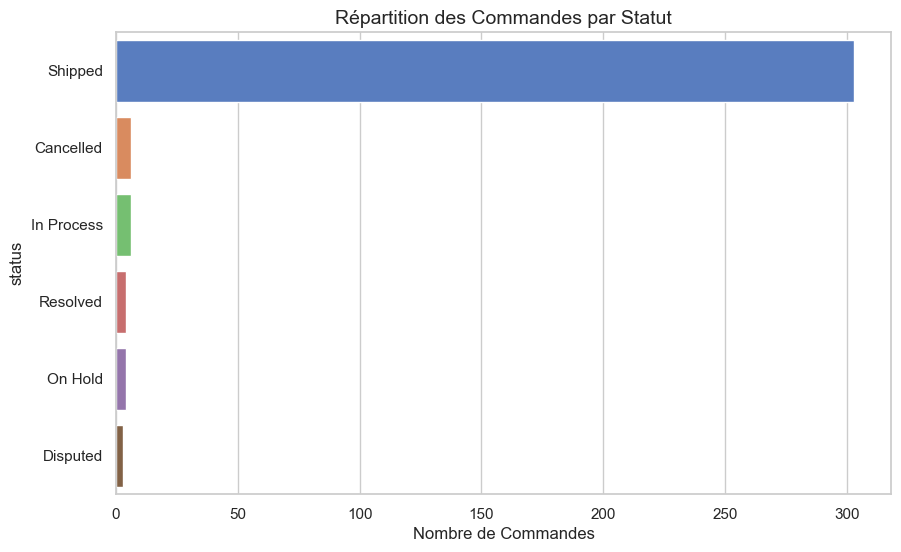

In [26]:
#-- --------------------------------------------
# 1. PARTIE 1: EXPLORATION VISUELLE
#-- --------------------------------------------
# --- 1.1 DISTRIBUTION DES STATUTS DE COMMANDE ---

# --- AJOUTE CES IMPORTS ICI ---
import matplotlib.pyplot as plt
import seaborn as sns
# ------------------------------

query_status = """
SELECT status, COUNT(*) as Nombre
FROM orders
GROUP BY status
ORDER BY Nombre DESC;
"""
df_status = pd.read_sql(query_status, conn)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_status, x='Nombre', y='status', palette='muted')
plt.title('Répartition des Commandes par Statut', fontsize=14)
plt.xlabel('Nombre de Commandes')

# Sauvegarde
plt.savefig("../visualizations/01_01_order_status.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/1552734008.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_stock = pd.read_sql(query_stock, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/1552734008.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_stock, x='Nombre_References', y='productLine', palette='Blues_d')


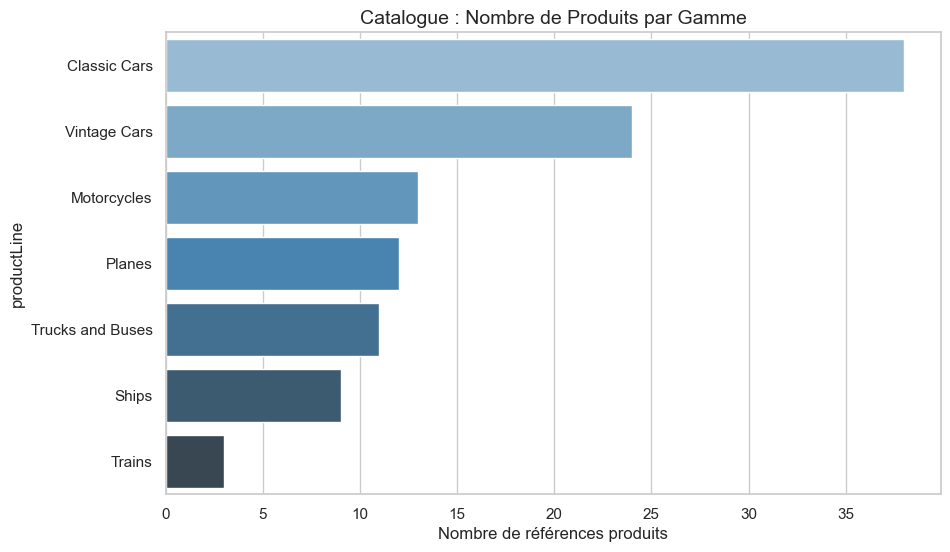

In [27]:
# --- 1.2 INVENTAIRE (Nombre de références par Gamme) ---

query_stock = """
SELECT productLine, COUNT(*) as Nombre_References
FROM products
GROUP BY productLine
ORDER BY Nombre_References DESC;
"""
df_stock = pd.read_sql(query_stock, conn)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_stock, x='Nombre_References', y='productLine', palette='Blues_d')
plt.title('Catalogue : Nombre de Produits par Gamme', fontsize=14)
plt.xlabel('Nombre de références produits')

# Sauvegarde
plt.savefig("../visualizations/01_02_product_count.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/1645286564.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_credit = pd.read_sql(query_credit, conn)


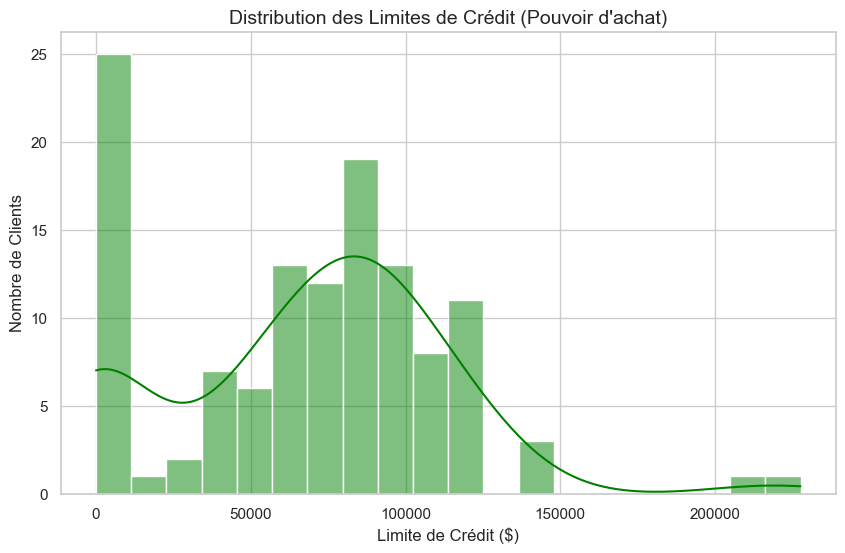

In [28]:
# --- 1.3 DISTRIBUTION DES LIMITES DE CRÉDIT CLIENTS ---

query_credit = "SELECT creditLimit FROM customers;"
df_credit = pd.read_sql(query_credit, conn)

plt.figure(figsize=(10, 6))
sns.histplot(df_credit['creditLimit'], bins=20, kde=True, color='green')
plt.title('Distribution des Limites de Crédit (Pouvoir d\'achat)', fontsize=14)
plt.xlabel('Limite de Crédit ($)')
plt.ylabel('Nombre de Clients')

# Sauvegarde
plt.savefig("../visualizations/01_03_credit_distribution.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/3986749514.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_offices = pd.read_sql(query_offices, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/3986749514.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_offices, x='Nb_Employes', y='Ville', palette='viridis')


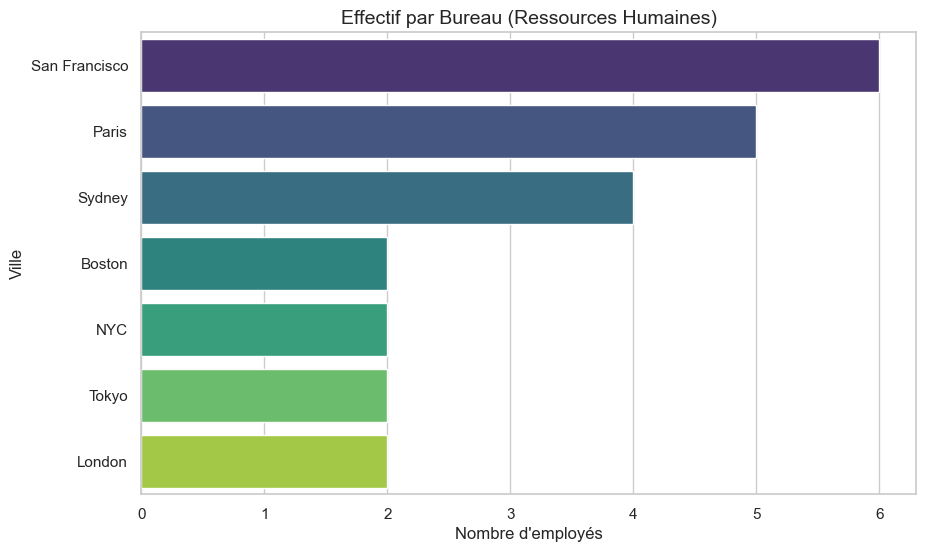

In [29]:
# --- 1.4 RÉPARTITION RH : Employés par Bureau ---

query_offices = """
SELECT o.city as Ville, COUNT(e.employeeNumber) as Nb_Employes
FROM offices o
JOIN employees e ON o.officeCode = e.officeCode
GROUP BY Ville
ORDER BY Nb_Employes DESC;
"""
df_offices = pd.read_sql(query_offices, conn)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_offices, x='Nb_Employes', y='Ville', palette='viridis')
plt.title('Effectif par Bureau (Ressources Humaines)', fontsize=14)
plt.xlabel('Nombre d\'employés')

# Sauvegarde
plt.savefig("../visualizations/01_04_employees_per_office.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/736679819.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pay_stats = pd.read_sql(query_pay_stats, conn)


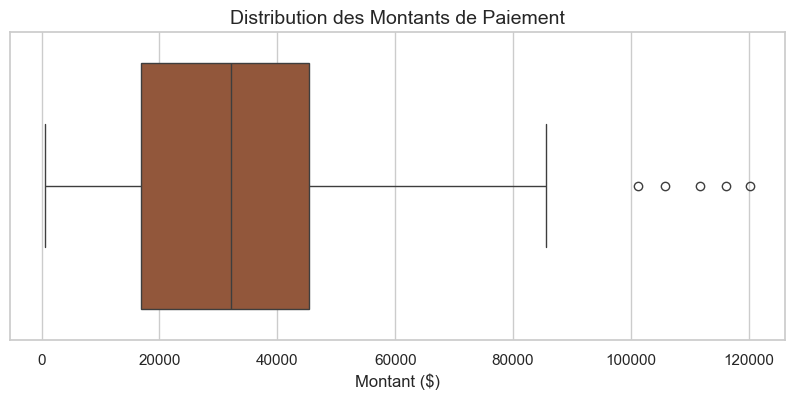

In [30]:
# --- 1.5 DISTRIBUTION DES PAIEMENTS (Boxplot) ---

query_pay_stats = "SELECT amount FROM payments;"
df_pay_stats = pd.read_sql(query_pay_stats, conn)

plt.figure(figsize=(10, 4))
sns.boxplot(x=df_pay_stats['amount'], color='sienna')
plt.title('Distribution des Montants de Paiement', fontsize=14)
plt.xlabel('Montant ($)')

# Sauvegarde
plt.savefig("../visualizations/01_05_payments_distribution.png", bbox_inches='tight')
plt.show()

In [37]:
#-- ---------------------------------------------
# PARTIE 2:REQUÊTES SQL AVANCÉES(PIVOT)
#-- ---------------------------------------------

# --- 5.1 SEGMENTATION AVANCÉE (JOINTURE 6 TABLES) ---
# On identifie les clients VIP, leur gamme préférée et leur total d'achats

query_complex_vip = """
SELECT 
    c.customerName,
    pl.productLine as Gamme_Preferee,
    COUNT(DISTINCT o.orderNumber) as Nb_Commandes,
    SUM(od.quantityOrdered * od.priceEach) as Total_Achat,
    MAX(p.paymentDate) as Dernier_Paiement
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
JOIN products pr ON od.productCode = pr.productCode
JOIN productlines pl ON pr.productLine = pl.productLine
JOIN payments p ON c.customerNumber = p.customerNumber
WHERE o.status = 'Shipped'
GROUP BY c.customerName, pl.productLine
HAVING Total_Achat > 5000
ORDER BY Total_Achat DESC
LIMIT 10;
"""
df_vip_complex = pd.read_sql(query_complex_vip, conn)

print("✅ Analyse VIP complexe chargée !")
display(df_vip_complex)

✅ Analyse VIP complexe chargée !


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/2959568540.py:27: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_vip_complex = pd.read_sql(query_complex_vip, conn)


,customerName,Gamme_Preferee,Nb_Commandes,Total_Achat,Dernier_Paiement
0,Euro+ Shopping Channel,Classic Cars,16,4706593.06,2005-05-19
1,Mini Gifts Distributors Ltd.,Classic Cars,14,2358740.61,2005-04-16
2,Euro+ Shopping Channel,Vintage Cars,12,1413541.87,2005-05-19
3,Mini Gifts Distributors Ltd.,Vintage Cars,12,1236330.18,2005-04-16
4,Euro+ Shopping Channel,Trucks and Buses,7,1103967.15,2005-05-19
5,Mini Gifts Distributors Ltd.,Trucks and Buses,9,1025743.32,2005-04-16
6,Muscle Machine Inc,Classic Cars,4,536240.52,2004-12-14
7,Euro+ Shopping Channel,Ships,3,522809.69,2005-05-19
8,Euro+ Shopping Channel,Trains,6,364585.65,2005-05-19
9,"Down Under Souveniers, Inc",Classic Cars,4,348409.32,2005-05-23


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/363121165.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_retention = pd.read_sql(query_retention, conn)


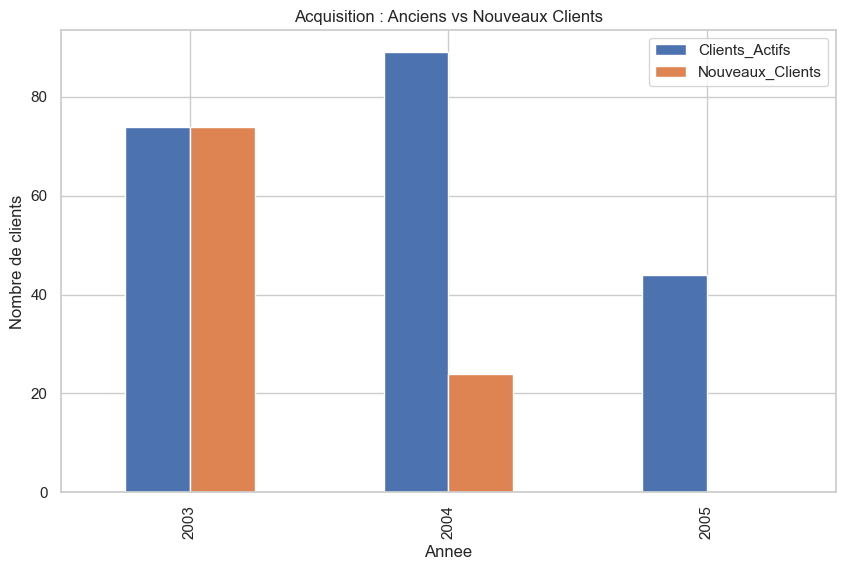

In [40]:
# --- 5.2 ANALYSE RÉTENTION (SOUS-REQUÊTE) ---
# On compte combien de Nouveaux Clients on a gagné par an
import matplotlib.pyplot as plt
import seaborn as sns
# --- 5.2 ANALYSE RÉTENTION (VERSION CORRIGÉE) ---
# On utilise une jointure de deux sous-tables pour éviter l'erreur de GROUP BY

query_retention = """
SELECT 
    T_Global.Annee,
    T_Global.Clients_Actifs,
    IFNULL(T_New.Nouveaux_Clients, 0) as Nouveaux_Clients
FROM
    -- Table 1 : Clients Actifs par an
    (SELECT YEAR(orderDate) as Annee, COUNT(DISTINCT customerNumber) as Clients_Actifs 
     FROM orders GROUP BY Annee) as T_Global
LEFT JOIN
    -- Table 2 : Nouveaux Clients par an (ceux dont c'est la 1ère commande)
    (SELECT YEAR(min_date) as Annee, COUNT(*) as Nouveaux_Clients
     FROM (SELECT customerNumber, MIN(orderDate) as min_date FROM orders GROUP BY customerNumber) as sub
     GROUP BY Annee) as T_New
ON T_Global.Annee = T_New.Annee
ORDER BY T_Global.Annee;
"""
df_retention = pd.read_sql(query_retention, conn)

# Graphique
df_retention.set_index('Annee')[['Clients_Actifs', 'Nouveaux_Clients']].plot(kind='bar', figsize=(10, 6))
plt.title('Acquisition : Anciens vs Nouveaux Clients')
plt.ylabel('Nombre de clients')

# Sauvegarde
plt.savefig("../visualizations/05_retention_fixed.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/2625943683.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pivot_data = pd.read_sql(query_pivot, conn)


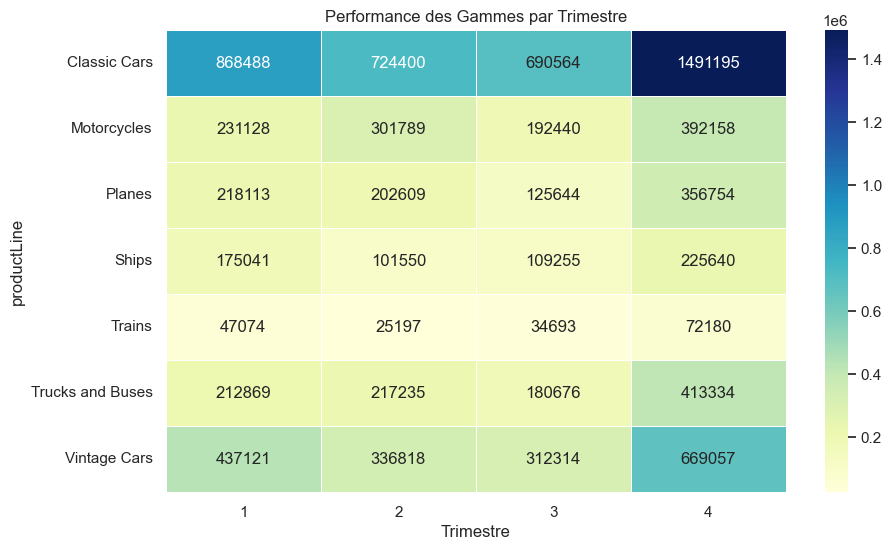

In [41]:
# --- 5.3 TABLEAU PIVOT (HEATMAP) ---

query_pivot = """
SELECT 
    p.productLine,
    QUARTER(o.orderDate) as Trimestre,
    SUM(od.quantityOrdered * od.priceEach) as CA
FROM orders o
JOIN orderdetails od ON o.orderNumber = od.orderNumber
JOIN products p ON od.productCode = p.productCode
WHERE o.status != 'Cancelled'
GROUP BY p.productLine, Trimestre;
"""
df_pivot_data = pd.read_sql(query_pivot, conn)

# On utilise la puissance de Python pour créer le pivot
pivot_table = df_pivot_data.pivot_table(
    index='productLine', 
    columns='Trimestre', 
    values='CA', 
    aggfunc='sum'
).fillna(0)

# Affichage en Heatmap (Carte de chaleur)
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5)
plt.title('Performance des Gammes par Trimestre')

# Sauvegarde
plt.savefig("../visualizations/05_pivot_heatmap.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/2841921005.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sales = pd.read_sql(query_sales, conn)


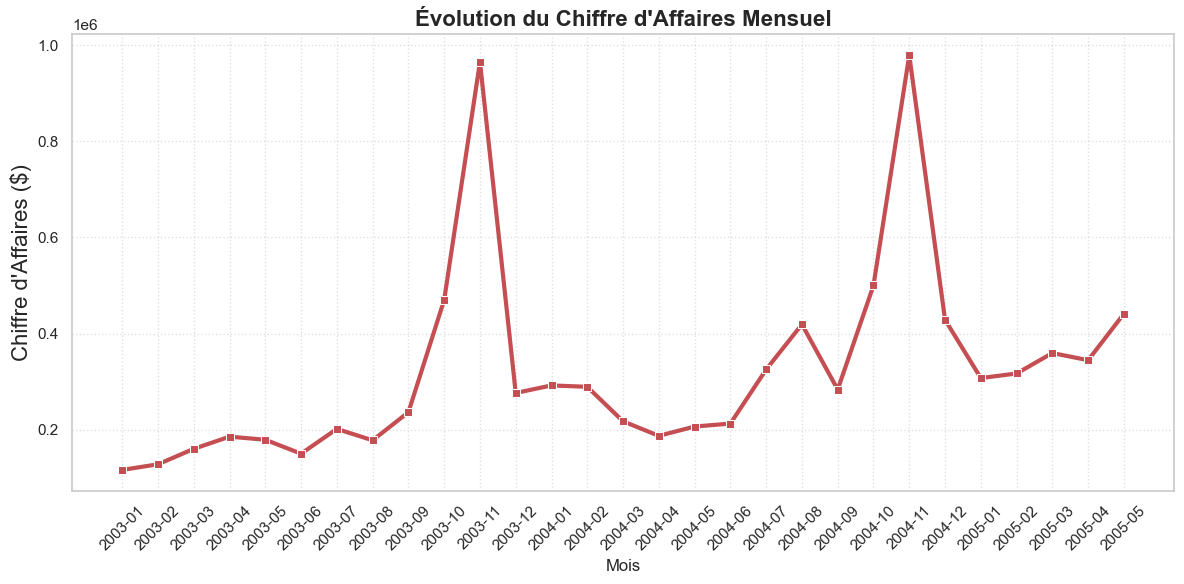

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
#-- -------------------------------------------------
# PARTIE 3: VISUALISATIONS PYTHON
#-- -------------------------------------------------
# 1. La Requête SQL (On récupère le CA par mois)
query_sales = """
SELECT 
    DATE_FORMAT(o.orderDate, '%Y-%m') as Mois,
    SUM(od.quantityOrdered * od.priceEach) as Chiffre_Affaires
FROM orders o
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Mois
ORDER BY Mois;
"""

# 2. je charge les données dans un DataFrame
df_sales = pd.read_sql(query_sales, conn)

# 3. je dessine le graphique
plt.figure(figsize=(12, 6)) # Taille de l'image
sns.set_theme(style="whitegrid") 

# Création de la courbe
sns.lineplot(data=df_sales, x='Mois', y='Chiffre_Affaires', marker='s', color='r', linewidth=3)

# 4. Mise en forme
plt.title('Évolution du Chiffre d\'Affaires Mensuel', fontsize=16, fontweight='bold')
plt.xlabel('Mois', fontsize=12)
plt.ylabel('Chiffre d\'Affaires ($)', fontsize=16)
plt.xticks(rotation=45) # On penche les dates pour qu'elles soient lisibles
plt.grid(True, linestyle=':', alpha=0.6)

# Affichage
plt.tight_layout()
plt.savefig("../visualizations/Evolution_CA_Mensuel.png", bbox_inches='tight')
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/2800336619.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_products = pd.read_sql(query_products, conn)


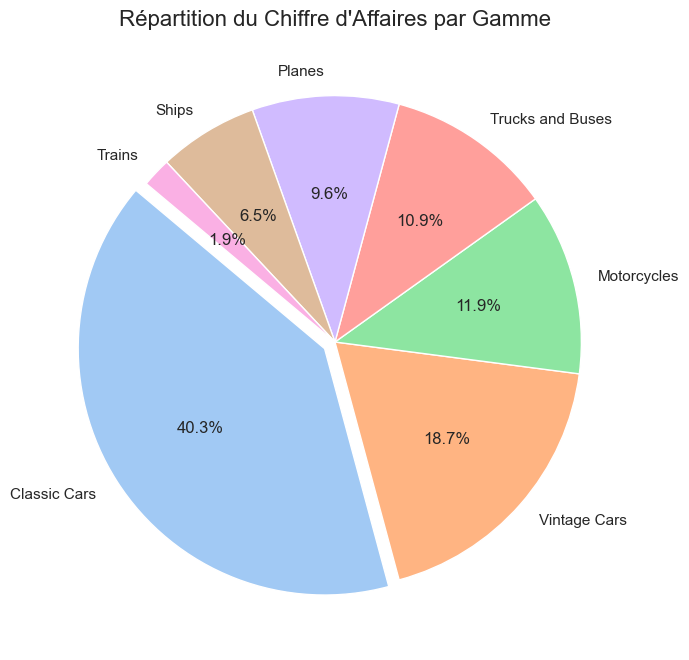

In [32]:
# 1. La Requête SQL (Total ventes par Gamme)
query_products = """
SELECT 
    p.productLine,
    SUM(od.quantityOrdered * od.priceEach) as Total_Ventes
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY p.productLine
ORDER BY Total_Ventes DESC;
"""

# 2. Chargement
df_products = pd.read_sql(query_products, conn)

# 3. Le Graphique (Pie Chart)
plt.figure(figsize=(8, 8))

# je définit des couleurs pastels 
colors = sns.color_palette('pastel')[0:7]

plt.pie(df_products['Total_Ventes'], 
        labels=df_products['productLine'], 
        autopct='%1.1f%%', # Affiche les pourcentages
        startangle=140, 
        colors=colors,
        explode=(0.05, 0, 0, 0, 0, 0, 0)) # "Détache" la première part (Voitures)

plt.title('Répartition du Chiffre d\'Affaires par Gamme', fontsize=16)
plt.savefig("../visualizations/Répartition_du Chiffre_d\'Affaires_Mensuel.png", bbox_inches='tight')
plt.show()

###  Analyse de la répartition <span style="color:purple">des ventes</span>

On observe une forte dépendance envers une seule catégorie :
* Les <b style="color:blue">**Classic Cars</b>**40.3%** du chiffre d'affaires total.
* Les <b style="color:red">**Vintage Cars</b>**arrivent en seconde position avec environ 20%.

**Conclusion :** L'entreprise est très exposée au marché de l'automobile de collection (plus de 60% des revenus cumulés). Une diversification vers les *Motos* ou les *Avions* pourrait réduire ce risque.
**Remarque :** Si demain la mode des voitures classiques passe, l'entreprise perd 40% de son chiffre d'affaires.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/534840411.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_countries = pd.read_sql(query_countries, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/534840411.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_countries, x='Total_Ventes', y='Pays', palette='Spectral')


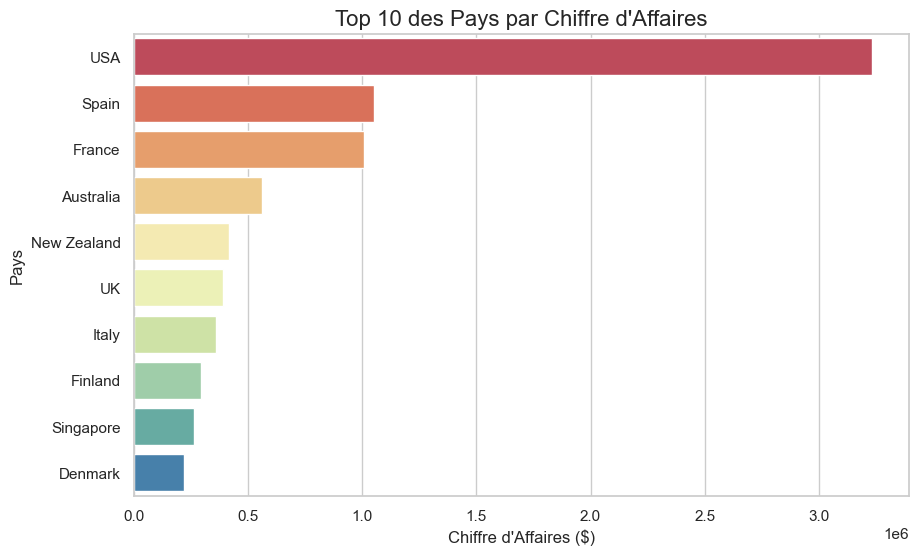

In [33]:
# 1. La Requête (Top 10 Pays par Chiffre d'Affaires)
query_countries = """
SELECT 
    c.country as Pays,
    SUM(od.quantityOrdered * od.priceEach) as Total_Ventes
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Pays
ORDER BY Total_Ventes DESC
LIMIT 10;
"""

# 2. Chargement
df_countries = pd.read_sql(query_countries, conn)

# 3. Le Graphique
plt.figure(figsize=(10, 6))

# j'utilise une palette de couleurs "Spectral"
sns.barplot(data=df_countries, x='Total_Ventes', y='Pays', palette='Spectral')

plt.title('Top 10 des Pays par Chiffre d\'Affaires', fontsize=16)
plt.xlabel('Chiffre d\'Affaires ($)')
plt.ylabel('Pays')
plt.savefig("../visualizations/Top 10 des Pays Par Chiffre d\'Affaires.png", bbox_inches='tight')
plt.show()

###  Analyse Géographique : La domination Américaine

Ce graphique met en évidence une **disparité géographique majeure** dans notre chiffre d'affaires :

1.  **Le Géant Américain :**
    * Les **États-Unis** dominent écrasant le classement.
    * À eux seuls, ils génèrent plus de chiffre d'affaires que les **3 pays suivants réunis** (Espagne, France, Australie).
    * C'est notre "vache à lait" (Cash Cow), mais c'est aussi un **risque** : si le marché US s'effondre, l'entreprise est en danger.

2.  **Le Pôle Européen :**
    * L'Europe est notre second moteur de croissance, tiré par le trio **<span style="color:red">Espagne</span>**, **<span style="color:blue">France</span>** et **Royaume-Uni**.
    * Ces marchés montrent un fort potentiel mais restent loin derrière les USA.

**Recommandation  :**
Il est crucial de **sécuriser** le marché américain tout en **investissant massivement en Europe** pour rééquilibrer les revenus. Une campagne marketing ciblée en *France* et en *Espagne* pourrait offrir le meilleur retour sur investissement (ROI).

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/4134307053.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top_products = pd.read_sql(query_top_products, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/4134307053.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_products, x='Total_Vendus', y='productName', palette='viridis')


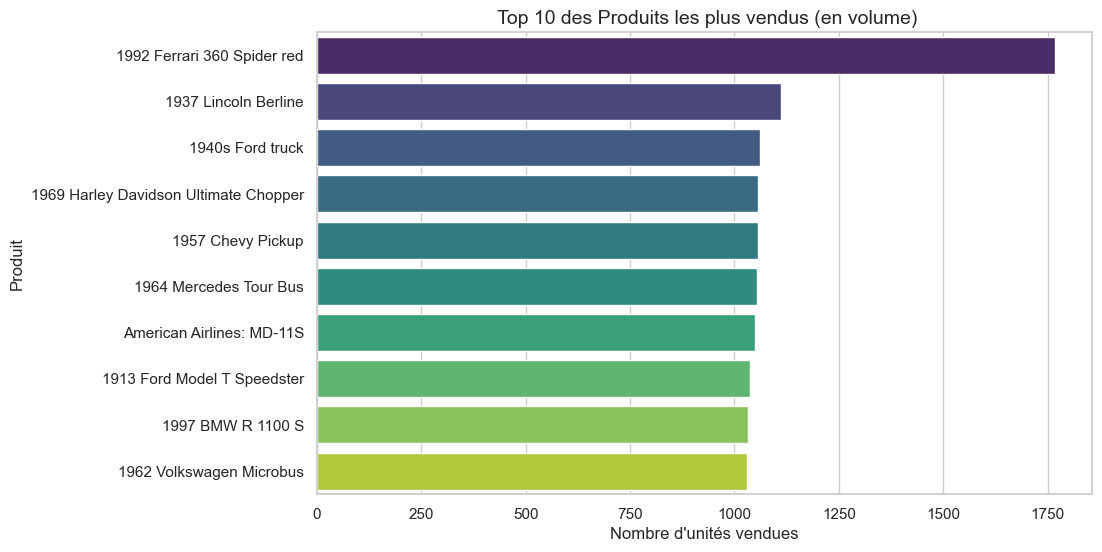

In [34]:
# --- VISUALISATION 4 : TOP 10 PRODUITS ---

# 1. Requête SQL
query_top_products = """
SELECT 
    p.productName, 
    SUM(od.quantityOrdered) as Total_Vendus
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY p.productName
ORDER BY Total_Vendus DESC
LIMIT 10;
"""

# 2. Chargement
df_top_products = pd.read_sql(query_top_products, conn)

# 3. Graphique
plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_products, x='Total_Vendus', y='productName', palette='viridis')

plt.title(' Top 10 des Produits les plus vendus (en volume)', fontsize=14)
plt.xlabel('Nombre d\'unités vendues')
plt.ylabel('Produit')
plt.savefig("../visualizations/Top 10 des Produits les plus vendus (en volume).png", bbox_inches='tight')
plt.show()

### Analyse des Best-Sellers

**Observation :**
Ce graphique identifie nos "produits stars" en termes de volume de vente.
* La **Ferrari 1992** (ou le modèle en tête) domine largement les commandes.
* On remarque que les modèles réduits de voitures anciennes (*Vintage Cars*) sont les plus populaires.

**Stratégie :**
Ces 10 produits sont essentiels pour attirer les clients. Il faut s'assurer qu'ils soient :
1.  Toujours mis en avant sur la page d'accueil du site.
2.  Jamais en rupture de stock (priorité logistique).

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/1008476175.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_stock = pd.read_sql(query_stock, conn)


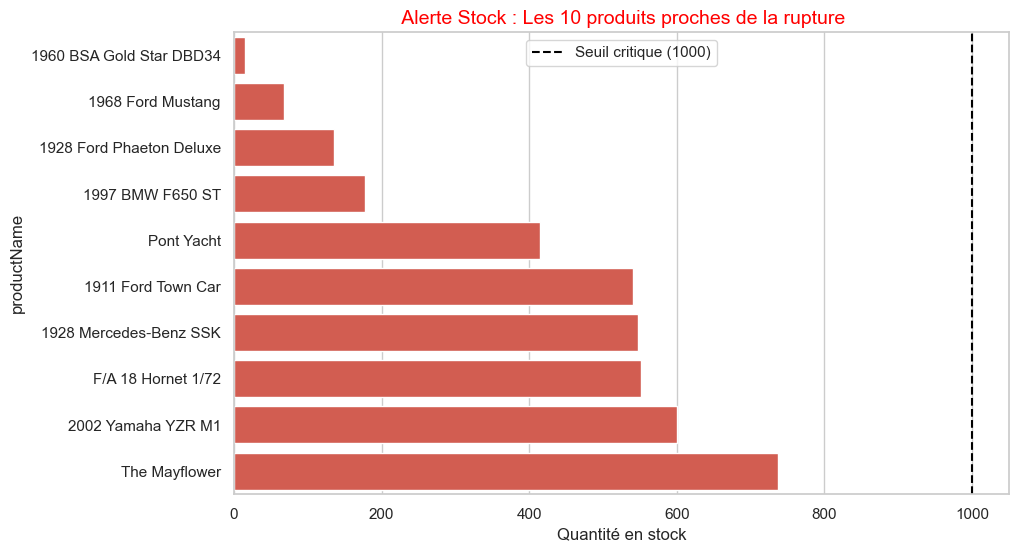

In [35]:
# --- VISUALISATION 5 : ÉTAT DES STOCKS CRITIQUES ---

# 1. Requête (Les 10 produits avec le stock le plus bas)
query_stock = """
SELECT productName, quantityInStock, productLine 
FROM products 
ORDER BY quantityInStock ASC 
LIMIT 10;
"""

df_stock = pd.read_sql(query_stock, conn)

# 2. Graphique
plt.figure(figsize=(10, 6))
# On utilise une couleur rouge pour signaler l'urgence
sns.barplot(data=df_stock, x='quantityInStock', y='productName', color='#e74c3c')

plt.title(' Alerte Stock : Les 10 produits proches de la rupture', fontsize=14, color='red')
plt.xlabel('Quantité en stock')
plt.axvline(x=1000, color='black', linestyle='--', label='Seuil critique (1000)') # Ligne de seuil
plt.legend()
plt.savefig("../visualizations/Alerte Stock: Les 10 produits proches de la rupture.png", bbox_inches='tight')
plt.show()

###  Alerte Logistique : Risque de Rupture

**Diagnostic Critique :**
Le graphique met en évidence 10 produits dont le stock est dangereusement bas (souvent sous les 1000 unités ou proche de 0).
* Si ces produits tombent à 0, nous perdons des ventes directes (Manque à gagner).
* Certains produits très demandés risquent la rupture imminente.

**Action Requise :**
Déclencher un **réapprovisionnement immédiat** auprès des fournisseurs pour ces 10 références afin d'éviter le "Stock-out" avant la fin du trimestre.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_29006/2721299864.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pareto = pd.read_sql(query_pareto, conn)


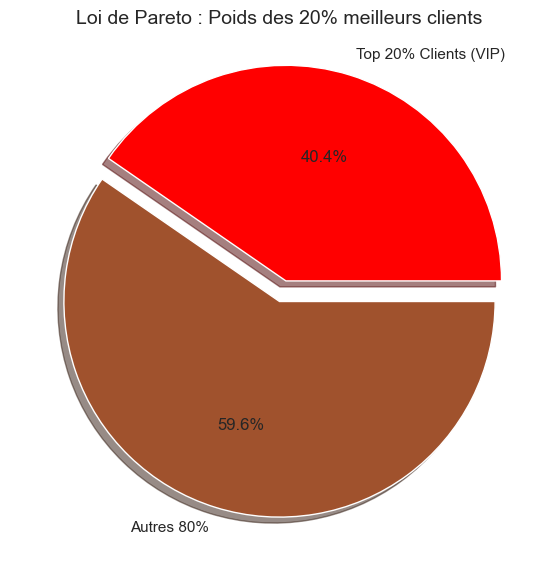

In [36]:
# --- VISUALISATION 6 : PARETO DES CLIENTS ---

# 1. On récupère le CA par client
query_pareto = """
SELECT 
    c.customerName,
    SUM(od.quantityOrdered * od.priceEach) as CA
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY c.customerName
ORDER BY CA DESC;
"""

df_pareto = pd.read_sql(query_pareto, conn)

# 2. Calculs Python (On divise en "Top 20%" et "Autres")
top_20_count = int(len(df_pareto) * 0.2)
top_clients = df_pareto.head(top_20_count)['CA'].sum()
other_clients = df_pareto.iloc[top_20_count:]['CA'].sum()

# 3. Graphique Camembert Comparatif
plt.figure(figsize=(7, 7))
plt.pie([top_clients, other_clients], 
        labels=['Top 20% Clients (VIP)', 'Autres 80%'], 
        autopct='%1.1f%%', 
        colors=['red', 'sienna'],
        explode=(0.1, 0), # On détache la part VIP
        shadow=True)

plt.title('Loi de Pareto : Poids des 20% meilleurs clients', fontsize=14)
plt.savefig("../visualizations/Loi de Pareto : Poids des 20% meilleurs clients.png", bbox_inches='tight')
plt.show()

###  Analyse de Pareto (Loi des 80/20)

**Constat Frappant :**
Nous observons une forte concentration du chiffre d'affaires :
* Une minorité de clients (nos **VIP**) génère une part disproportionnée des revenus.
* C'est la confirmation classique de la loi de Pareto : environ **20% des clients rapportent 80% du CA** (ou s'en approchent).

**Recommandation CRM :**
* **Pour les VIP (Partie red) :** Il faut absolument les fidéliser (Service client dédié, offres exclusives, cadeaux) car le départ d'un seul de ces clients impacterait lourdement le CA.
* **Pour les Autres (Partie sienna) :** Mettre en place des campagnes d'emailing automatisées pour essayer de les faire passer dans la catégorie supérieure.